# 2. PPA pricing and structure comparison

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-trading/ppa-pricing-market-analyzer/notebooks/02_ppa_pricing_and_structures.ipynb)

How an originator prices a pay-as-produced PPA for a 10 MW solar or wind plant, delivery 2027 to 2029, and how the producer's revenue compares across structures.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-trading/ppa-pricing-market-analyzer"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "ppalab").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: ppa-pricing-market-analyzer


In [2]:
from ppalab import market as M, trends as T, pricing as P, bess as B, crm as C
d = M.load()
h = T.enrich(d["hourly"])
print(len(h), "hours from", h.timestamp.min().date(), "to", h.timestamp.max().date())

68664 hours from 2019-01-01 to 2026-10-31


## Hourly price forward curve

Shape factors from the last 24 months, scaled so the curve averages exactly to the traded Cal-27 base and peak.

In [3]:
c27 = d["curve"].query("year == 2027").iloc[0]
hp = P.hpfc(d["hourly"], 2027, c27.base_eur_mwh, c27.peak_eur_mwh)
print("base", round(hp.price.mean(), 2), "peak", round(hp[hp.is_peak].price.mean(), 2))
hp.pivot_table(index=hp.timestamp.dt.month, columns=hp.timestamp.dt.hour, values="price").iloc[[0, 5], ::3].round(1)

base 72.33 peak 73.04


timestamp,0,3,6,9,12,15,18,21
timestamp,,,,,,,,
1,65.8,66.0,68.8,77.2,54.4,74.7,94.5,69.1
6,93.0,90.9,80.5,49.3,31.8,51.5,85.9,95.6


## Fundamental Monte Carlo

Each scenario simulates the delivery years with that year's installed capacity and new weather, then rescales the price level to the forward times a shock whose spread grows with time to delivery. 40 scenarios here to keep the notebook quick; the pipeline uses 100.

In [4]:
scen = P.scenarios([2027, 2028, 2029], 40, d["curve"], float(T.forward_volatility(d["cal27"]).annualised_vol.iloc[-1]))
stats = {t: P.asset_stats(scen, t, 10.0) for t in ("solar", "wind")}
stats["solar"].describe().loc[["mean", "std", "min", "max"]].round(2)

,scenario,potential_mwh,paid_mwh,capture_all,capture_paid,base_eur_mwh,curtailed_share,capture_rate
mean,19.50,28501.15,25057.32,51.04,62.11,69.59,0.12,0.89
std,11.69,310.13,293.09,10.19,12.13,13.05,0.01,0.01
min,0.00,27938.17,24549.34,30.63,38.66,44.15,0.10,0.86
max,39.00,29372.67,25771.75,79.24,95.24,103.91,0.15,0.93


In [5]:
offers = {t: P.offer(stats[t], t, 3, "BBB") for t in stats}
pd.DataFrame(offers).round(2)

,solar,wind
forward_base,69.59,69.59
shape,-18.55,-4.54
curtailment_uplift,11.07,3.42
expected_capture,62.11,68.47
balancing,-1.60,-2.80
hedging,-0.35,-0.35
profile_risk,-0.51,-0.35
volume_risk,-0.53,-1.58
credit,-0.09,-0.09
margin,-1.00,-1.00


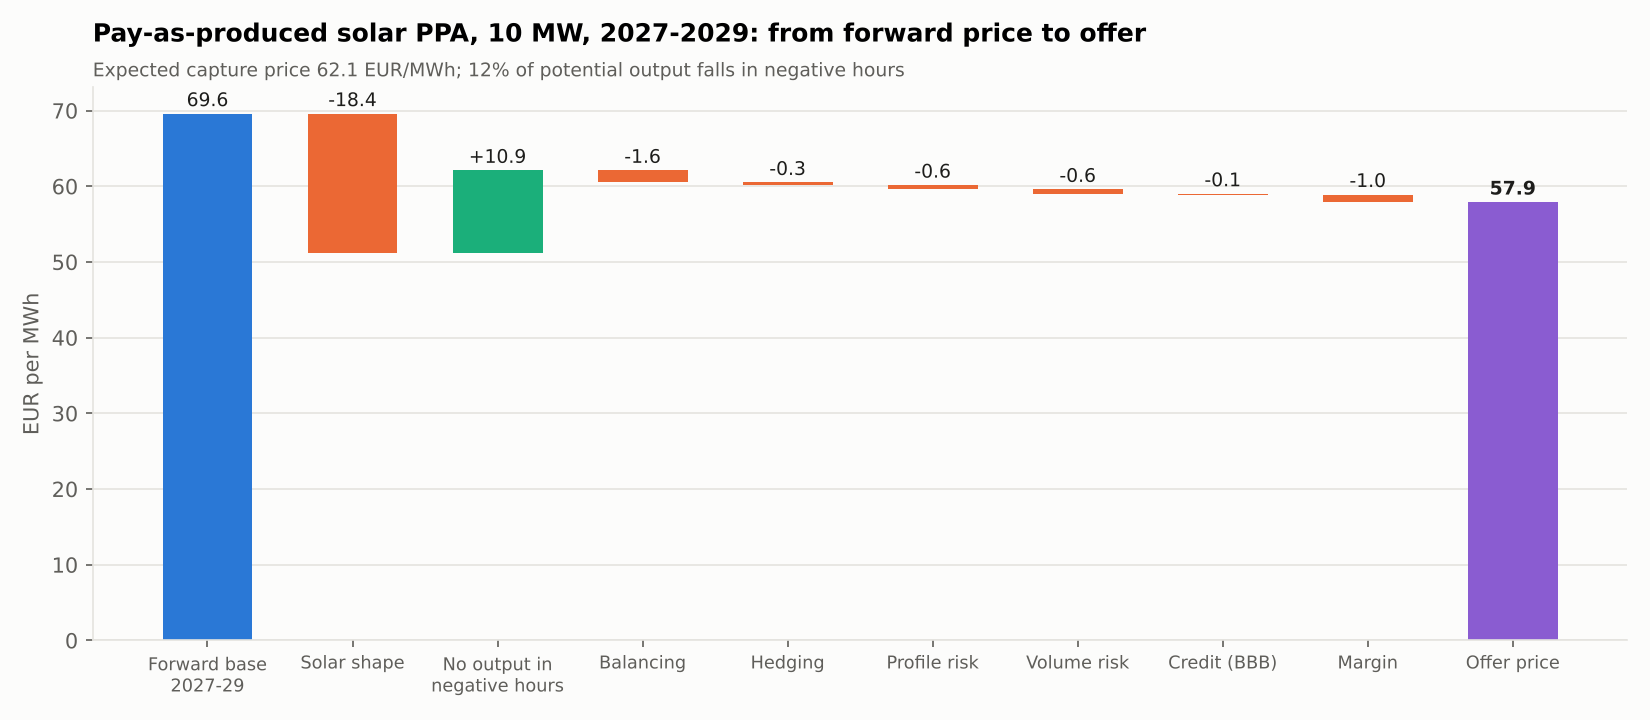

In [6]:
display(Image("outputs/figures/offer_waterfall.png"))

## Who carries which risk

The same scenarios, seen from the producer. Pay-as-produced removes all uncertainty for a lower expected price; a baseload PPA keeps the shape and volume risk with the producer; merchant keeps everything.

In [7]:
base_price = d["curve"].query("year in [2027, 2028, 2029]").base_eur_mwh.mean() - 1.5
for t in ("solar", "wind"):
    print(t)
    print(P.summarise_structures(P.structures(scen, t, 10.0, offers[t]["offer_price"], base_price)), "\n")

solar
                 expected  P90 (bad case)  P10 (good case)  spread P10-P90
merchant            62.11           49.99            76.96           26.97
pay_as_produced     58.03           58.03            58.03            0.00
baseload            60.42           55.92            63.59            7.67
swap                58.92           54.42            62.09            7.67 

wind
                 expected  P90 (bad case)  P10 (good case)  spread P10-P90
merchant            68.47           54.96            84.82           29.86
pay_as_produced     62.30           62.30            62.30            0.00
baseload            66.90           64.88            68.03            3.15
swap                65.40           63.38            66.53            3.15 



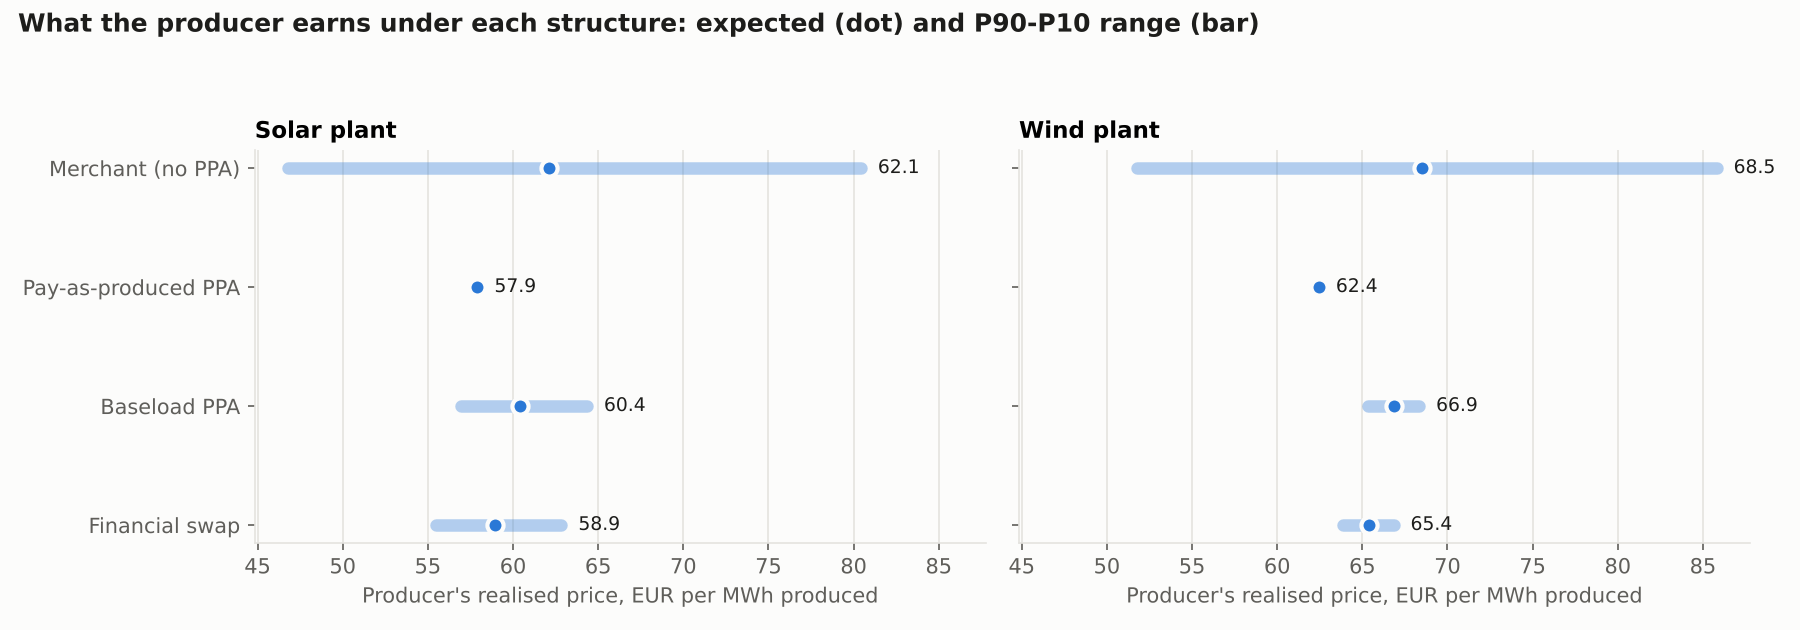

In [8]:
display(Image("outputs/figures/structures.png"))

The offer calculator in `outputs/ppa_offer_calculator.xlsx` reproduces the walk with live Excel formulas, so an originator can change capacity, tenor, rating or margin in front of a client.